# M11: Exploring Deep Learning Architectures

This notebook covers Parts A-E using PyTorch.

## Results Summary

- MLP test accuracy: **0.807**
- CNN test accuracy: **0.783**
- RNN final validation loss: **1.556**

See `results/metrics.json` and the exported PNG files for full saved outputs.

## Assumptions

- Fashion-MNIST is a local CSV subset with 1,000 train and 1,000 test rows.
- Tiny Shakespeare is truncated to 250,000 characters for CPU runtime.
- DCGAN was optional and not included.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

repo = Path('.')
metrics = json.loads((repo / 'results' / 'metrics.json').read_text())
metrics.keys()

dict_keys(['assumptions', 'mlp', 'cnn', 'rnn'])

## Part A: MLP

The saved run achieved **0.807** test accuracy.

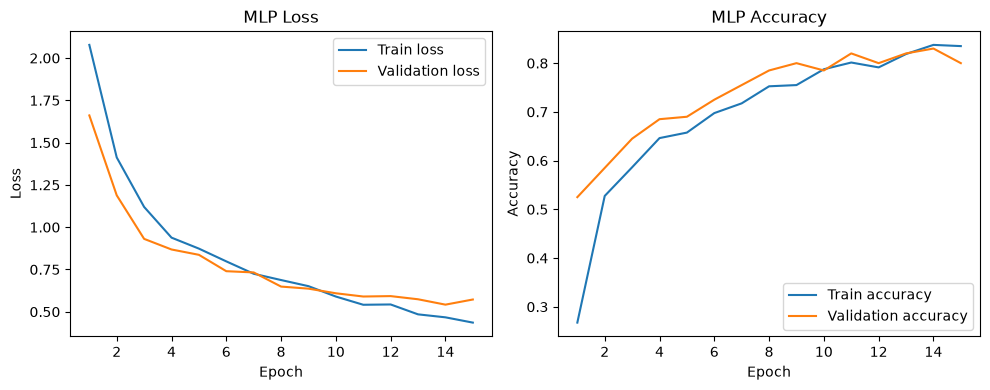

In [2]:
hist = metrics['mlp']['history']
epochs = range(1, len(hist['train_loss']) + 1)
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(epochs, hist['train_loss'], label='Train loss')
plt.plot(epochs, hist['val_loss'], label='Validation loss')
plt.title('MLP Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.subplot(1,2,2)
plt.plot(epochs, hist['train_acc'], label='Train accuracy')
plt.plot(epochs, hist['val_acc'], label='Validation accuracy')
plt.title('MLP Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

## Part B: CNN

The saved run achieved **0.783** test accuracy.

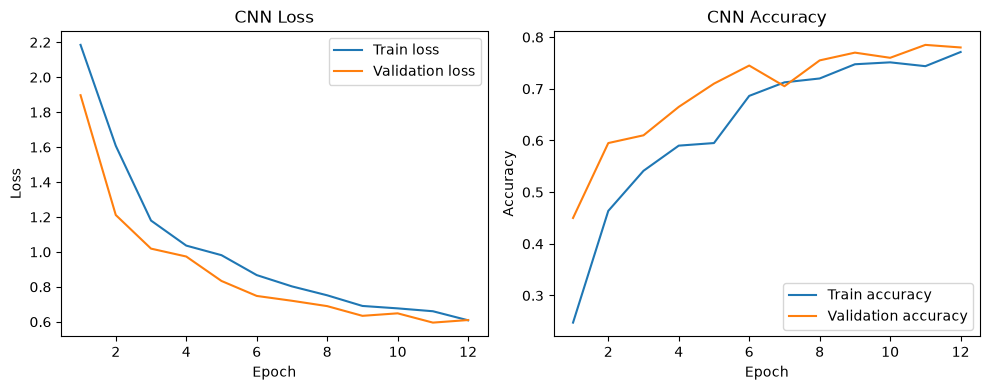

In [3]:
hist = metrics['cnn']['history']
epochs = range(1, len(hist['train_loss']) + 1)
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(epochs, hist['train_loss'], label='Train loss')
plt.plot(epochs, hist['val_loss'], label='Validation loss')
plt.title('CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.subplot(1,2,2)
plt.plot(epochs, hist['train_acc'], label='Train accuracy')
plt.plot(epochs, hist['val_acc'], label='Validation accuracy')
plt.title('CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

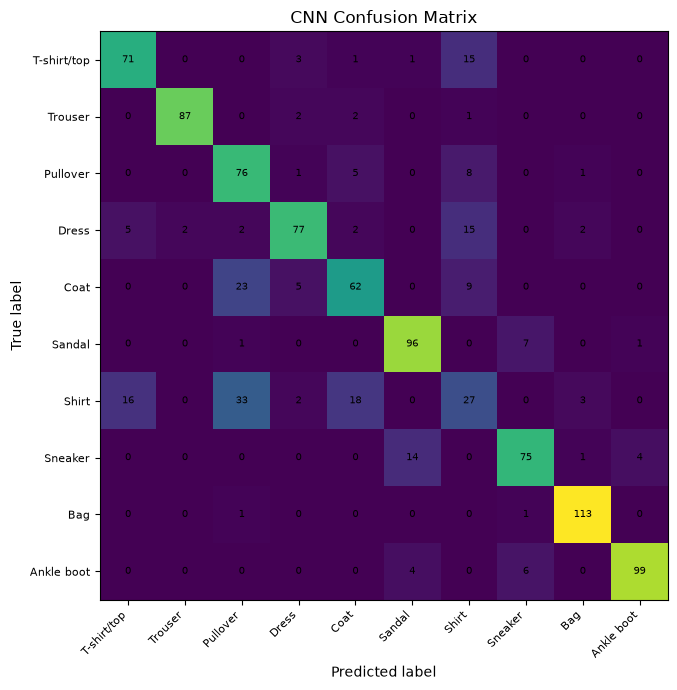

In [4]:
cm = np.array(metrics['cnn']['confusion_matrix'])
class_names = ['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
plt.figure(figsize=(7,7))
plt.imshow(cm, interpolation='nearest')
plt.title('CNN Confusion Matrix')
plt.xticks(range(len(class_names)), class_names, rotation=45, ha='right', fontsize=8)
plt.yticks(range(len(class_names)), class_names, fontsize=8)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, int(cm[i, j]), ha='center', va='center', fontsize=7)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.tight_layout()
plt.show()

Saved example figures are in `results/cnn_correct_examples.png` and `results/cnn_incorrect_examples.png`.

## Part C: RNN / LSTM

The saved run reached final validation loss **1.556** and validation perplexity **4.74**.

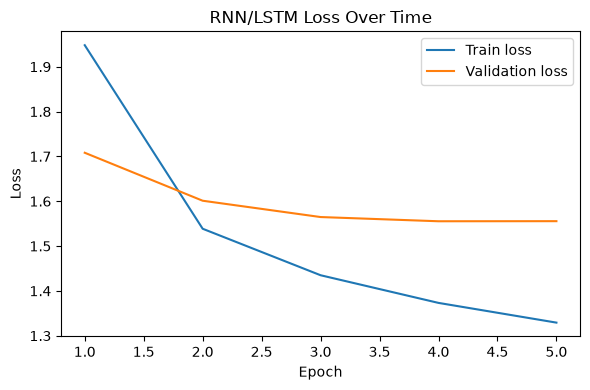

ROMEO:
Mestance to fellow?

CORIOLANUS:
Weat's of you:
He shall be said me, and would me
If a man can prevenge is surefore.

MENENIUS:
Do not his death.

AUFIDIUS:
Marcius, and their hornous most
Mank how those have her husband


In [5]:
hist = metrics['rnn']['history']
epochs = range(1, len(hist['train_loss']) + 1)
plt.figure(figsize=(6,4))
plt.plot(epochs, hist['train_loss'], label='Train loss')
plt.plot(epochs, hist['val_loss'], label='Validation loss')
plt.title('RNN/LSTM Loss Over Time')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()
print(metrics['rnn']['generated_text'])

## Reflection

The MLP ended up with the better test accuracy on this subset (0.807 against 0.783 for the CNN). I expected the CNN to win because it keeps the spatial structure that the MLP loses when it flattens each image. With only 800 training images and 12 epochs, the CNN did not get enough data to show that advantage, and a gap of 2.4 points on 1,000 test images is small enough to be run-to-run noise. The LSTM fit the sequence task because it modeled ordered text and generated partially Shakespeare-like output after a short training run.

The main limitation was dataset size. The local Fashion-MNIST files were much smaller than the full benchmark, which increased variance. The RNN was also slower to train than the image models because sequential computation is more expensive.

MLPs are useful for tabular data, CNNs are useful for vision tasks such as defect detection and retail image classification, and RNN/LSTMs are useful for sequence forecasting, text generation, and sentiment-style sequence problems.

## Part D

Optional DCGAN bonus work was not included.